In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/patelhiral/paysim-synthetic-financial-transactions-dataset/paysim.csv
/kaggle/input/datasets/patelhiral/cicids2017-network-intrusion-detection-dataset/MachineLearningCVE/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
/kaggle/input/datasets/patelhiral/cicids2017-network-intrusion-detection-dataset/MachineLearningCVE/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
/kaggle/input/datasets/patelhiral/cicids2017-network-intrusion-detection-dataset/MachineLearningCVE/Tuesday-WorkingHours.pcap_ISCX.csv
/kaggle/input/datasets/patelhiral/cicids2017-network-intrusion-detection-dataset/MachineLearningCVE/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
/kaggle/input/datasets/patelhiral/cicids2017-network-intrusion-detection-dataset/MachineLearningCVE/Monday-WorkingHours.pcap_ISCX.csv
/kaggle/input/datasets/patelhiral/cicids2017-network-intrusion-detection-dataset/MachineLearningCVE/Friday-WorkingHours-Morning.pcap_ISCX.csv
/kaggle/input/datasets/patelhiral/cicid

In [2]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import MinMaxScaler, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_style("whitegrid")
print("Libraries loaded")

Libraries loaded


In [3]:
all_files = [os.path.join(r, f) for r, _, fs in os.walk("/kaggle/input")
             for f in fs if f.endswith(".csv")]

paysim_files = [f for f in all_files if "PS_" in f or "paysim" in f.lower()]
cic_files    = [f for f in all_files if f not in paysim_files]

print("PaySim files:")
for f in paysim_files: print("  ", f)
print("CICIDS2017 files:")
for f in cic_files: print("  ", f)

PaySim files:
   /kaggle/input/datasets/patelhiral/paysim-synthetic-financial-transactions-dataset/paysim.csv
CICIDS2017 files:
   /kaggle/input/datasets/patelhiral/cicids2017-network-intrusion-detection-dataset/MachineLearningCVE/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
   /kaggle/input/datasets/patelhiral/cicids2017-network-intrusion-detection-dataset/MachineLearningCVE/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
   /kaggle/input/datasets/patelhiral/cicids2017-network-intrusion-detection-dataset/MachineLearningCVE/Tuesday-WorkingHours.pcap_ISCX.csv
   /kaggle/input/datasets/patelhiral/cicids2017-network-intrusion-detection-dataset/MachineLearningCVE/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
   /kaggle/input/datasets/patelhiral/cicids2017-network-intrusion-detection-dataset/MachineLearningCVE/Monday-WorkingHours.pcap_ISCX.csv
   /kaggle/input/datasets/patelhiral/cicids2017-network-intrusion-detection-dataset/MachineLearningCVE/Friday-WorkingHours-Morning.

In [4]:
paysim = pd.read_csv(paysim_files[0])

cic_parts = []
for f in cic_files:
    part = pd.read_csv(f, encoding="latin1", low_memory=False)
    part.columns = part.columns.str.strip()      # CICIDS columns have leading spaces
    part["source_file"] = os.path.basename(f)
    cic_parts.append(part)
cic = pd.concat(cic_parts, ignore_index=True)
del cic_parts

print("PaySim:", paysim.shape)
print("CICIDS2017:", cic.shape)

PaySim: (6362620, 11)
CICIDS2017: (2830743, 80)


In [5]:
print("===== PAYSIM =====")
display(paysim.head())
print("\n Paysim Info:")
paysim.info()
print("\n Paysim Describe:")
display(paysim.describe().T)
print("\n", paysim['type'].value_counts())
print("\n", paysim['isFraud'].value_counts())

===== PAYSIM =====


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.640",C1231006815,"170,136.000","160,296.360",M1979787155,0.000,0.000,0,0
1,1,PAYMENT,"1,864.280",C1666544295,"21,249.000","19,384.720",M2044282225,0.000,0.000,0,0
2,1,TRANSFER,181.000,C1305486145,181.000,0.000,C553264065,0.000,0.000,1,0
3,1,CASH_OUT,181.000,C840083671,181.000,0.000,C38997010,"21,182.000",0.000,1,0
4,1,PAYMENT,"11,668.140",C2048537720,"41,554.000","29,885.860",M1230701703,0.000,0.000,0,0



 Paysim Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB

 Paysim Describe:


,count,mean,std,min,25%,50%,75%,max
step,"6,362,620.000",243.397,142.332,1.000,156.000,239.000,335.000,743.000
amount,"6,362,620.000","179,861.904","603,858.231",0.000,"13,389.570","74,871.940","208,721.478","92,445,516.640"
oldbalanceOrg,"6,362,620.000","833,883.104","2,888,242.673",0.000,0.000,"14,208.000","107,315.175","59,585,040.370"
newbalanceOrig,"6,362,620.000","855,113.669","2,924,048.503",0.000,0.000,0.000,"144,258.410","49,585,040.370"
oldbalanceDest,"6,362,620.000","1,100,701.667","3,399,180.113",0.000,0.000,"132,705.665","943,036.708","356,015,889.350"
newbalanceDest,"6,362,620.000","1,224,996.398","3,674,128.942",0.000,0.000,"214,661.440","1,111,909.250","356,179,278.920"
isFraud,"6,362,620.000",0.001,0.036,0.000,0.000,0.000,0.000,1.000
isFlaggedFraud,"6,362,620.000",0.000,0.002,0.000,0.000,0.000,0.000,1.000



 type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

 isFraud
0    6354407
1       8213
Name: count, dtype: int64


In [6]:
print("\n===== CICIDS2017 =====")
display(cic.head())
print("\n CICIDS2017 Info:")
print(cic.dtypes.value_counts())
print("\n CICIDS2017 Describe:")
display(cic.describe().T.head(5))
print(cic['Label'].value_counts())


===== CICIDS2017 =====


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,source_file
0,22,1266342,41,44,2664,6954,456,0,64.976,109.865,976,0,158.045,312.675,"7,595.105",67.122,"15,075.500","104,051.400",948537,0,1266342,"31,658.550","159,355.259",996324,2,317671,"7,387.698","19,636.448",104616,1,0,0,0,0,1328,1424,32.377,34.746,0,976,111.837,239.687,"57,449.785",0,0,0,1,0,0,0,0,1,113.153,64.976,158.045,1328,0,0,0,0,0,0,41,2664,44,6954,29200,243,24,32,0.000,0.000,0,0,0.000,0.000,0,0,BENIGN,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...
1,22,1319353,41,44,2664,6954,456,0,64.976,109.865,976,0,158.045,312.675,"7,289.937",64.426,"15,706.583","104,861.870",955790,1,1319353,"32,983.825","159,247.901",996423,1,363429,"8,451.837","21,337.263",104815,1,0,0,0,0,1328,1424,31.076,33.350,0,976,111.837,239.687,"57,449.785",0,0,0,1,0,0,0,0,1,113.153,64.976,158.045,1328,0,0,0,0,0,0,41,2664,44,6954,29200,243,24,32,0.000,0.000,0,0,0.000,0.000,0,0,BENIGN,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...
2,22,160,1,1,0,0,0,0,0.000,0.000,0,0,0.000,0.000,0.000,"12,500.000",160.000,0.000,160,160,0,0.000,0.000,0,0,0,0.000,0.000,0,0,0,0,0,0,32,32,"6,250.000","6,250.000",0,0,0.000,0.000,0.000,0,0,0,0,1,1,0,0,1,0.000,0.000,0.000,32,0,0,0,0,0,0,1,0,1,0,290,243,0,32,0.000,0.000,0,0,0.000,0.000,0,0,BENIGN,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...
3,22,1303488,41,42,2728,6634,456,0,66.537,110.130,976,0,157.952,319.121,"7,182.268",63.675,"15,896.195","106,554.899",956551,0,1303488,"32,587.200","160,397.050",997357,1,346851,"8,459.780","23,962.239",138295,0,0,0,0,0,1328,1360,31.454,32.221,0,976,111.452,241.643,"58,391.239",0,0,0,1,0,0,0,0,1,112.795,66.537,157.952,1328,0,0,0,0,0,0,41,2728,42,6634,29200,243,24,32,0.000,0.000,0,0,0.000,0.000,0,0,BENIGN,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...
4,35396,77,1,2,0,0,0,0,0.000,0.000,0,0,0.000,0.000,0.000,"38,961.039",38.500,14.849,49,28,0,0.000,0.000,0,0,49,49.000,0.000,49,49,0,0,0,0,32,64,"12,987.013","25,974.026",0,0,0.000,0.000,0.000,0,0,0,0,1,1,0,0,2,0.000,0.000,0.000,32,0,0,0,0,0,0,1,0,2,0,243,290,0,32,0.000,0.000,0,0,0.000,0.000,0,0,BENIGN,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...



 CICIDS2017 Info:
int64      54
float64    24
object      2
Name: count, dtype: int64

 CICIDS2017 Describe:


,count,mean,std,min,25%,50%,75%,max
Destination Port,"2,830,743.000","8,071.483","18,283.632",0.000,53.000,80.000,443.000,"65,535.000"
Flow Duration,"2,830,743.000","14,785,663.930","33,653,744.086",-13.000,155.000,"31,316.000","3,204,828.500","119,999,998.000"
Total Fwd Packets,"2,830,743.000",9.361,749.673,1.000,2.000,2.000,5.000,"219,759.000"
Total Backward Packets,"2,830,743.000",10.394,997.388,0.000,1.000,2.000,4.000,"291,922.000"
Total Length of Fwd Packets,"2,830,743.000",549.302,"9,993.589",0.000,12.000,62.000,187.000,"12,900,000.000"


Label
BENIGN                          2273097
DoS Hulk                         231073
PortScan                         158930
DDoS                             128027
DoS GoldenEye                     10293
FTP-Patator                        7938
SSH-Patator                        5897
DoS slowloris                      5796
DoS Slowhttptest                   5499
Bot                                1966
Web Attack ï¿½ Brute Force         1507
Web Attack ï¿½ XSS                  652
Infiltration                         36
Web Attack ï¿½ Sql Injection         21
Heartbleed                           11
Name: count, dtype: int64


In [7]:
print("--- PaySim ---")
print("Missing values:", paysim.isnull().sum().sum())
print("Duplicate rows:", paysim.duplicated().sum())
print("Negative amounts:", (paysim['amount'] < 0).sum())
print("isFraud values:", paysim['isFraud'].unique())
print("Types:", paysim['type'].unique())

--- PaySim ---
Missing values: 0
Duplicate rows: 0
Negative amounts: 0
isFraud values: [0 1]
Types: ['PAYMENT' 'TRANSFER' 'CASH_OUT' 'DEBIT' 'CASH_IN']


In [8]:
print("--- CICIDS2017 ---")
cic_num = cic.select_dtypes(include=np.number)
print("Missing values:", cic.isnull().sum().sum())
print("Infinite values:", np.isinf(cic_num).sum().sum())
print("Duplicate rows:", cic.duplicated().sum())

print("\n--- Integration check ---")
print("Common columns:", set(paysim.columns) & set(cic.columns))

--- CICIDS2017 ---
Missing values: 1358
Infinite values: 4376
Duplicate rows: 256479

--- Integration check ---
Common columns: set()


In [9]:
# CICIDS Data Cleaning
before = len(cic)
cic = cic.replace([np.inf, -np.inf], np.nan)
cic = cic.dropna().drop_duplicates().reset_index(drop=True)
print(f"CICIDS rows: {before:,} -> {len(cic):,}")

# Clean label text (removes odd characters like in 'Web Attack – Brute Force')
cic['Label'] = (cic['Label'].astype(str)
                .str.replace(r'[^A-Za-z0-9]+', ' ', regex=True).str.strip())

# Memory reduction
for c in cic.select_dtypes('float64').columns:
    cic[c] = cic[c].astype('float32')

print(cic['Label'].value_counts())

CICIDS rows: 2,830,743 -> 2,572,640
Label
BENIGN                      2146899
DoS Hulk                     172846
DDoS                         128014
PortScan                      90694
DoS GoldenEye                 10286
FTP Patator                    5931
DoS slowloris                  5385
DoS Slowhttptest               5228
SSH Patator                    3219
Bot                            1948
Web Attack Brute Force         1470
Web Attack XSS                  652
Infiltration                     36
Web Attack Sql Injection         21
Heartbleed                       11
Name: count, dtype: int64


In [10]:
print("--- CICIDS2017 ---")
cic_num = cic.select_dtypes(include=np.number)
print("Missing values:", cic.isnull().sum().sum())
print("Infinite values:", np.isinf(cic_num).sum().sum())
print("Duplicate rows:", cic.duplicated().sum())

--- CICIDS2017 ---
Missing values: 0
Infinite values: 0
Duplicate rows: 0


In [11]:
# ETL Pipeline
def group_label(x):
    x = x.lower()
    if x == 'benign':          return 'Benign'
    if 'ddos' in x:            return 'DDoS'
    if 'dos' in x:             return 'DoS'
    if 'portscan' in x:        return 'PortScan'
    if 'patator' in x:         return 'Brute Force (FTP/SSH)'
    if 'web attack' in x:      return 'Web Attack'
    if 'bot' in x:             return 'Botnet'
    if 'infil' in x:           return 'Infiltration'
    if 'heartbleed' in x:      return 'Heartbleed'
    return 'Other'

# Transform
paysim['fraud_label'] = paysim['isFraud'].map({0: 'Legitimate', 1: 'Fraud'})
mapping = {l: group_label(l) for l in cic['Label'].unique()}
cic['attack_group'] = cic['Label'].map(mapping)
cic['is_attack'] = (cic['attack_group'] != 'Benign').astype(int)

# Load
paysim.to_parquet('/kaggle/working/paysim_clean.parquet', index=False) 
cic.to_parquet('/kaggle/working/cicids_clean.parquet', index=False)


print(mapping)
print(cic['attack_group'].value_counts())

{'BENIGN': 'Benign', 'PortScan': 'PortScan', 'Web Attack Brute Force': 'Web Attack', 'Web Attack XSS': 'Web Attack', 'Web Attack Sql Injection': 'Web Attack', 'FTP Patator': 'Brute Force (FTP/SSH)', 'SSH Patator': 'Brute Force (FTP/SSH)', 'DDoS': 'DDoS', 'Bot': 'Botnet', 'Infiltration': 'Infiltration', 'DoS slowloris': 'DoS', 'DoS Slowhttptest': 'DoS', 'DoS Hulk': 'DoS', 'DoS GoldenEye': 'DoS', 'Heartbleed': 'Heartbleed'}
attack_group
Benign                   2146899
DoS                       193745
DDoS                      128014
PortScan                   90694
Brute Force (FTP/SSH)       9150
Web Attack                  2143
Botnet                      1948
Infiltration                  36
Heartbleed                    11
Name: count, dtype: int64


CICIDS key columns: ['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Flow Bytes/s', 'Flow Packets/s', 'Packet Length Mean', 'Average Packet Size']


,step,day,hour,time_of_day,amount,amount_band
0,1,1,0,Night (0-5),"9,839.640",1K-10K
1,1,1,0,Night (0-5),"1,864.280",1K-10K
2,1,1,0,Night (0-5),181.000,Under 1K
3,1,1,0,Night (0-5),181.000,Under 1K
4,1,1,0,Night (0-5),"11,668.140",10K-100K


,transactions,fraud_count,fraud_rate_%
amount_band,,,
Under 1K,142646,58,0.041
1K-10K,1143445,220,0.019
10K-100K,2239207,1429,0.064
100K-1M,2706696,3800,0.140
Over 1M,130626,2706,2.072


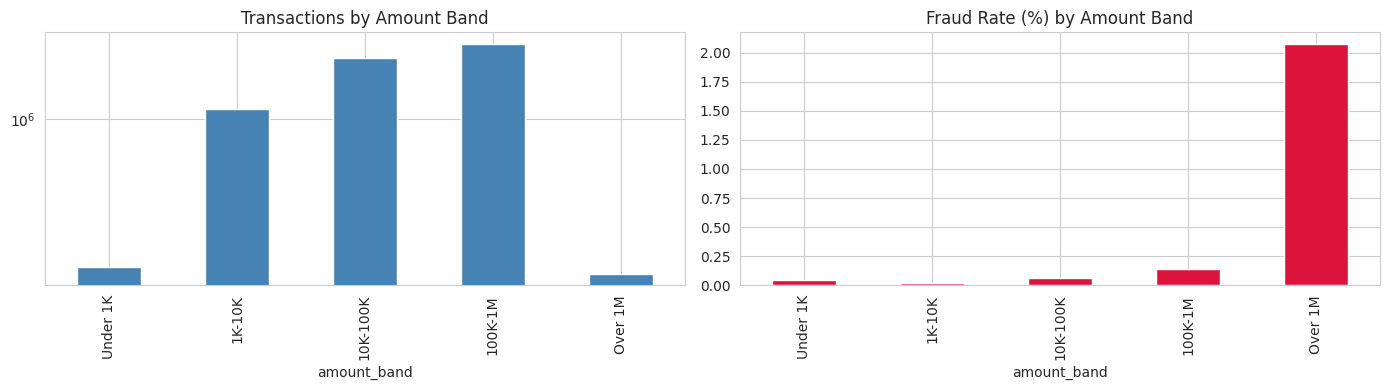

In [12]:
# Data Transformation
# PaySim
paysim['type'] = paysim['type'].astype('category')

# step = 1 hour of simulation (starts at 1)
paysim['hour'] = (paysim['step'] - 1) % 24
paysim['day']  = (paysim['step'] - 1) // 24 + 1

paysim['time_of_day'] = pd.cut(paysim['hour'], bins=[-1, 5, 11, 17, 23],
                           labels=['Night (0-5)', 'Morning (6-11)',
                                   'Afternoon (12-17)', 'Evening (18-23)'])

paysim['amount_band'] = pd.cut(paysim['amount'],
                           bins=[-0.01, 1_000, 10_000, 100_000, 1_000_000, np.inf],
                           labels=['Under 1K', '1K-10K', '10K-100K', '100K-1M', 'Over 1M'])

ps_num = ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']

# ---------------- CICIDS2017 ----------------
cic['attack_group'] = cic['attack_group'].astype('category')

cic_key = [c for c in ['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets',
                       'Flow Bytes/s', 'Flow Packets/s', 'Packet Length Mean',
                       'Average Packet Size'] if c in cic.columns]

# Flow Duration is in microseconds -> convert to seconds
if 'Flow Duration' in cic.columns:
    cic['flow_duration_sec'] = cic['Flow Duration'] / 1_000_000
    cic['duration_band'] = pd.cut(cic['flow_duration_sec'],
                                  bins=[-np.inf, 0.001, 1, 10, 60, np.inf],
                                  labels=['Under 1 ms', '1 ms-1 s', '1-10 s', '10-60 s', 'Over 1 min'])

print("CICIDS key columns:", cic_key)
display(paysim[['step', 'day', 'hour', 'time_of_day', 'amount', 'amount_band']].head())

# Readable summary: transactions and fraud rate per amount band
band_summary = paysim.groupby('amount_band', observed=True)['isFraud'].agg(['count', 'sum', 'mean'])
band_summary.columns = ['transactions', 'fraud_count', 'fraud_rate']
band_summary['fraud_rate_%'] = band_summary['fraud_rate'] * 100
display(band_summary.drop(columns='fraud_rate').round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
band_summary['transactions'].plot.bar(ax=ax[0], color='steelblue')
ax[0].set_title('Transactions by Amount Band'); ax[0].set_yscale('log')
band_summary['fraud_rate_%'].plot.bar(ax=ax[1], color='crimson')
ax[1].set_title('Fraud Rate (%) by Amount Band')
plt.tight_layout(); plt.show()

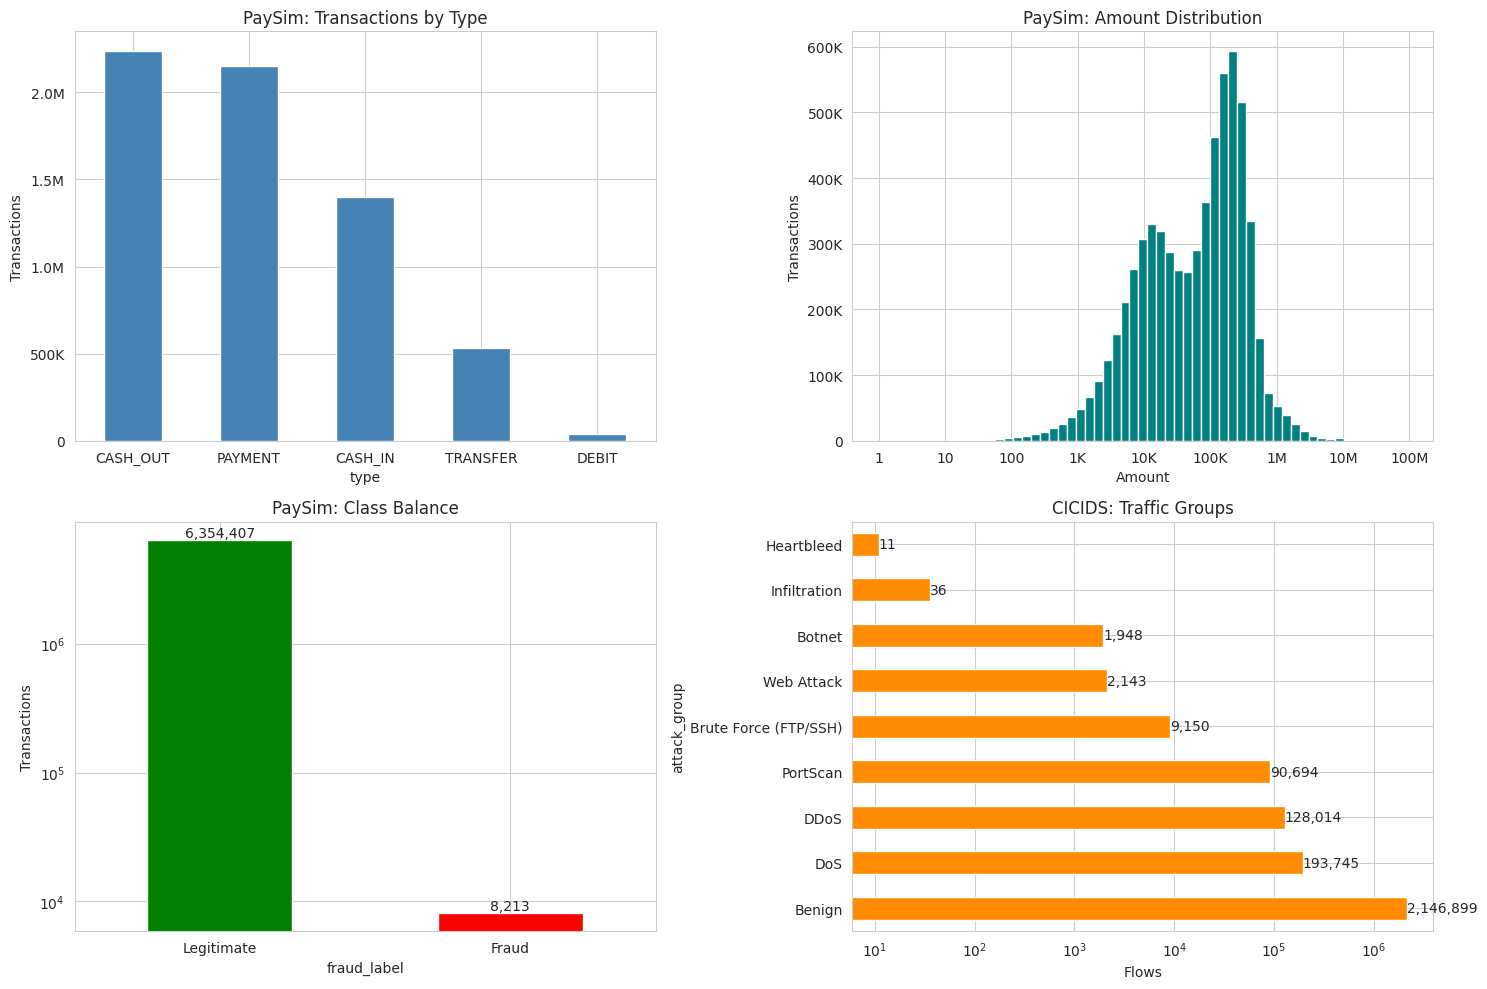

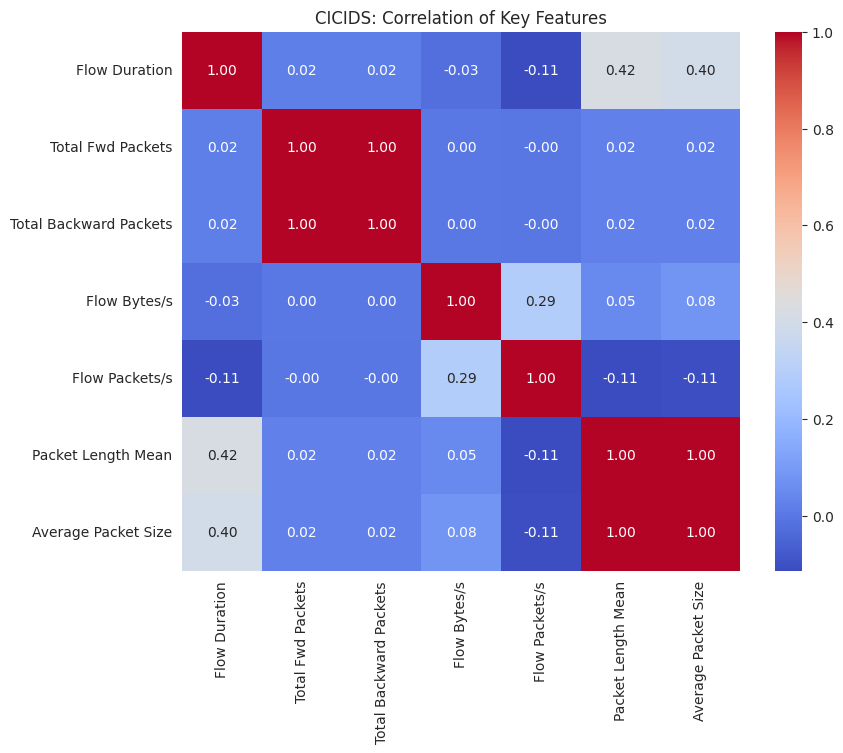

In [13]:
# Exploratory Data Analysis
from matplotlib.ticker import FuncFormatter

def money(x, pos=None):
    if x >= 1e6: return f'{x/1e6:.0f}M'
    if x >= 1e3: return f'{x/1e3:.0f}K'
    return f'{x:.0f}'

def count_fmt(x, pos=None):
    if x >= 1e6: return f'{x/1e6:.1f}M'
    if x >= 1e3: return f'{x/1e3:.0f}K'
    return f'{x:.0f}'

fig, ax = plt.subplots(2, 2, figsize=(15, 10))

# 1. Transactions by type
paysim['type'].value_counts().plot.bar(ax=ax[0, 0], color='steelblue')
ax[0, 0].set_title('PaySim: Transactions by Type')
ax[0, 0].set_ylabel('Transactions')
ax[0, 0].yaxis.set_major_formatter(FuncFormatter(count_fmt))
ax[0, 0].tick_params(axis='x', rotation=0)

# 2. Amount distribution (original values, log-spaced axis, real labels)
ax[0, 1].hist(paysim['amount'].clip(lower=1), bins=np.logspace(0, np.log10(paysim['amount'].max()), 60),
              color='teal')
ax[0, 1].set_xscale('log')
ax[0, 1].xaxis.set_major_formatter(FuncFormatter(money))
ax[0, 1].set_title('PaySim: Amount Distribution')
ax[0, 1].set_xlabel('Amount'); ax[0, 1].set_ylabel('Transactions')
ax[0, 1].yaxis.set_major_formatter(FuncFormatter(count_fmt))

# 3. Class balance
paysim['fraud_label'].value_counts().plot.bar(ax=ax[1, 0], color=['green', 'red'])
ax[1, 0].set_yscale('log')
ax[1, 0].set_title('PaySim: Class Balance')
ax[1, 0].set_ylabel('Transactions')
ax[1, 0].tick_params(axis='x', rotation=0)
for p in ax[1, 0].patches:
    ax[1, 0].annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2, p.get_height()),
                      ha='center', va='bottom')

# 4. CICIDS traffic groups
cic['attack_group'].value_counts().plot.barh(ax=ax[1, 1], color='darkorange')
ax[1, 1].set_xscale('log')
ax[1, 1].set_title('CICIDS: Traffic Groups')
ax[1, 1].set_xlabel('Flows')
for p in ax[1, 1].patches:
    ax[1, 1].annotate(f'{int(p.get_width()):,}', (p.get_width(), p.get_y() + p.get_height() / 2),
                      va='center', ha='left')

plt.tight_layout(); plt.show()

# 5. Correlation of key CICIDS features
plt.figure(figsize=(9, 7))
sns.heatmap(cic.sample(200000, random_state=42)[cic_key].corr(),
            annot=True, fmt='.2f', cmap='coolwarm')
plt.title('CICIDS: Correlation of Key Features'); plt.show()

In [14]:
def money(x, pos=None):
    if x >= 1e9: return f'{x/1e9:.1f}B'
    if x >= 1e6: return f'{x/1e6:.0f}M'
    if x >= 1e3: return f'{x/1e3:.0f}K'
    return f'{x:.0f}'

def count_fmt(x, pos=None):
    if x >= 1e6: return f'{x/1e6:.1f}M'
    if x >= 1e3: return f'{x/1e3:.0f}K'
    return f'{x:.0f}'

if 'is_drained' not in paysim:
    paysim['is_drained'] = ((paysim['oldbalanceOrg'] > 0) & (paysim['newbalanceOrig'] == 0)).astype(int)
if 'fraud_label' not in paysim:
    paysim['fraud_label'] = paysim['isFraud'].map({0: 'Legitimate', 1: 'Fraud'})
if 'day' not in cic:
    cic['day'] = cic['source_file'].str.split(r'[-_.]').str[0]

fraud = paysim[paysim['isFraud'] == 1]
att   = cic[cic['is_attack'] == 1]

feat = [c for c in cic_key + ['total_packets', 'total_bytes', 'bytes_per_packet', 'fwd_bwd_ratio']
        if c in cic.columns]
print("Fraud rows:", len(fraud), "| Attack flows:", len(att))

Fraud rows: 8213 | Attack flows: 425741


# 1. Which transaction types (CASH_OUT, TRANSFER, PAYMENT, DEBIT, CASH_IN) carry the highest fraud rate and highest fraud value?

,transactions,fraud_count,fraud_rate_%,fraud_value
type,,,,
TRANSFER,532909,4097,0.769,"6,067,213,184.010"
CASH_OUT,2237500,4116,0.184,"5,989,202,243.830"
CASH_IN,1399284,0,0.000,0.000
DEBIT,41432,0,0.000,0.000
PAYMENT,2151495,0,0.000,0.000


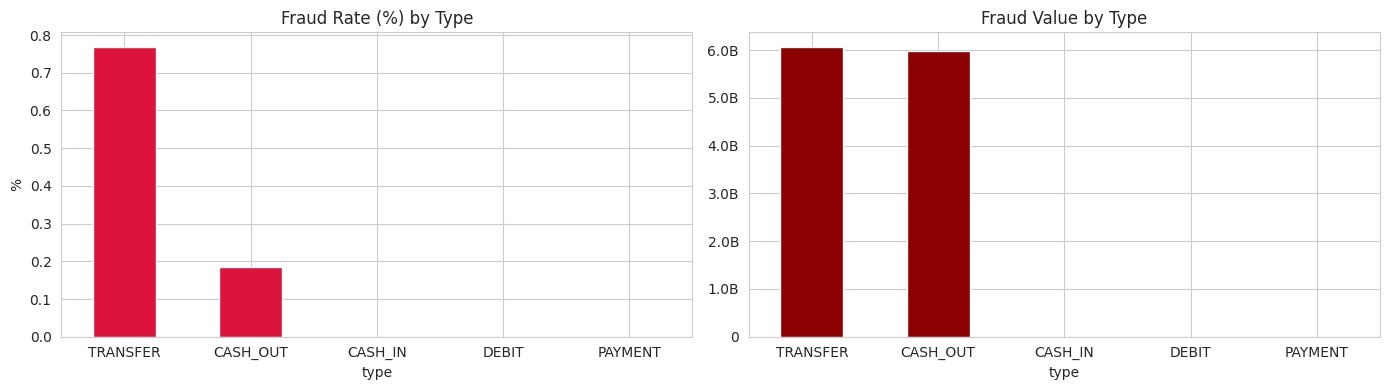

In [15]:
q1 = paysim.groupby('type', observed=True)['isFraud'].agg(transactions='size', fraud_count='sum')
q1['fraud_rate_%'] = q1['fraud_count'] / q1['transactions'] * 100
q1['fraud_value'] = fraud.groupby('type', observed=True)['amount'].sum()
q1 = q1.fillna(0).sort_values('fraud_value', ascending=False)
display(q1.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
q1['fraud_rate_%'].plot.bar(ax=ax[0], color='crimson')
ax[0].set_title('Fraud Rate (%) by Type'); ax[0].set_ylabel('%')
q1['fraud_value'].plot.bar(ax=ax[1], color='darkred')
ax[1].set_title('Fraud Value by Type'); ax[1].yaxis.set_major_formatter(FuncFormatter(money))
for a in ax: a.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

# 2. What percentage of total transaction volume and value is fraudulent, and what is the estimated financial loss?

Fraud transactions     : 8,213 of 6,362,620 (0.129% of volume)
Fraud value            : 12,056,415,428 of 1,144,392,944,760 (1.054% of value)
Estimated gross loss   : 12,056,415,428  (sum of all fraudulent amounts)
Average loss per fraud : 1,467,967


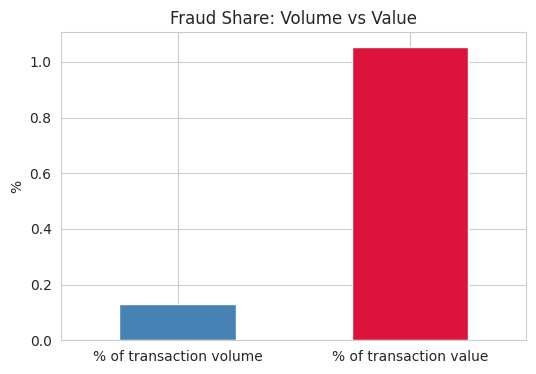

In [16]:
total_txn, total_val = len(paysim), paysim['amount'].sum()
fraud_txn, fraud_val = len(fraud), fraud['amount'].sum()

vol_pct = fraud_txn / total_txn * 100
val_pct = fraud_val / total_val * 100

print(f"Fraud transactions     : {fraud_txn:,} of {total_txn:,} ({vol_pct:.3f}% of volume)")
print(f"Fraud value            : {fraud_val:,.0f} of {total_val:,.0f} ({val_pct:.3f}% of value)")
print(f"Estimated gross loss   : {fraud_val:,.0f}  (sum of all fraudulent amounts)")
print(f"Average loss per fraud : {fraud_val/fraud_txn:,.0f}")

pd.Series({'% of transaction volume': vol_pct, '% of transaction value': val_pct}) \
  .plot.bar(color=['steelblue', 'crimson'], figsize=(6, 4))
plt.title('Fraud Share: Volume vs Value'); plt.ylabel('%'); plt.xticks(rotation=0); plt.show()

# 3. At what transaction amounts does fraud concentrate? Is there a "sweet spot" attackers prefer?

,transactions,fraud_count,fraud_rate_%,share_of_all_fraud_%
amount_band,,,,
Under 1K,142646,58,0.041,0.706
1K-10K,1143445,220,0.019,2.679
10K-100K,2239207,1429,0.064,17.399
100K-1M,2706696,3800,0.140,46.268
Over 1M,130626,2706,2.072,32.948


Middle 50% of fraud amounts: 127,091 to 1,517,771  (median 441,423)


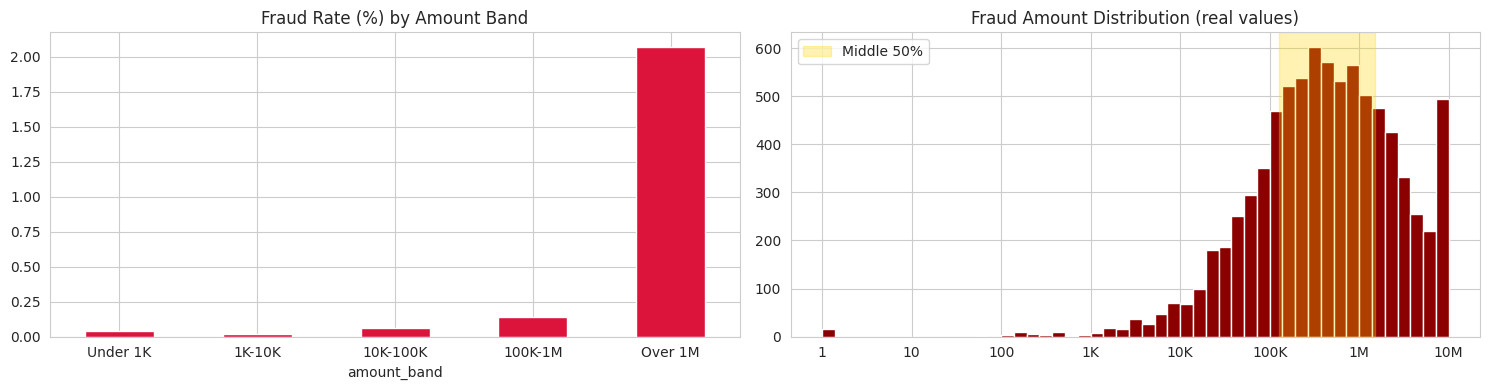

In [17]:
q3 = paysim.groupby('amount_band', observed=True)['isFraud'].agg(transactions='size', fraud_count='sum')
q3['fraud_rate_%'] = q3['fraud_count'] / q3['transactions'] * 100
q3['share_of_all_fraud_%'] = q3['fraud_count'] / q3['fraud_count'].sum() * 100
display(q3.round(3))

p25, p50, p75 = fraud['amount'].quantile([.25, .5, .75])
print(f"Middle 50% of fraud amounts: {p25:,.0f} to {p75:,.0f}  (median {p50:,.0f})")

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
q3['fraud_rate_%'].plot.bar(ax=ax[0], color='crimson')
ax[0].set_title('Fraud Rate (%) by Amount Band'); ax[0].tick_params(axis='x', rotation=0)

ax[1].hist(fraud['amount'].clip(lower=1), bins=np.logspace(0, np.log10(fraud['amount'].max()), 50), color='darkred')
ax[1].set_xscale('log'); ax[1].xaxis.set_major_formatter(FuncFormatter(money))
ax[1].axvspan(p25, p75, color='gold', alpha=0.3, label='Middle 50%')
ax[1].set_title('Fraud Amount Distribution (real values)'); ax[1].legend()
plt.tight_layout(); plt.show()

# 4. What is the average and maximum fraud amount per transaction type, and where is the loss concentrated?

,fraud_count,average,maximum,total,share_of_total_loss_%
type,,,,,
CASH_OUT,4116,"1,455,103.000","10,000,000.000","5,989,202,244.000",50.000
TRANSFER,4097,"1,480,892.000","10,000,000.000","6,067,213,184.000",50.000


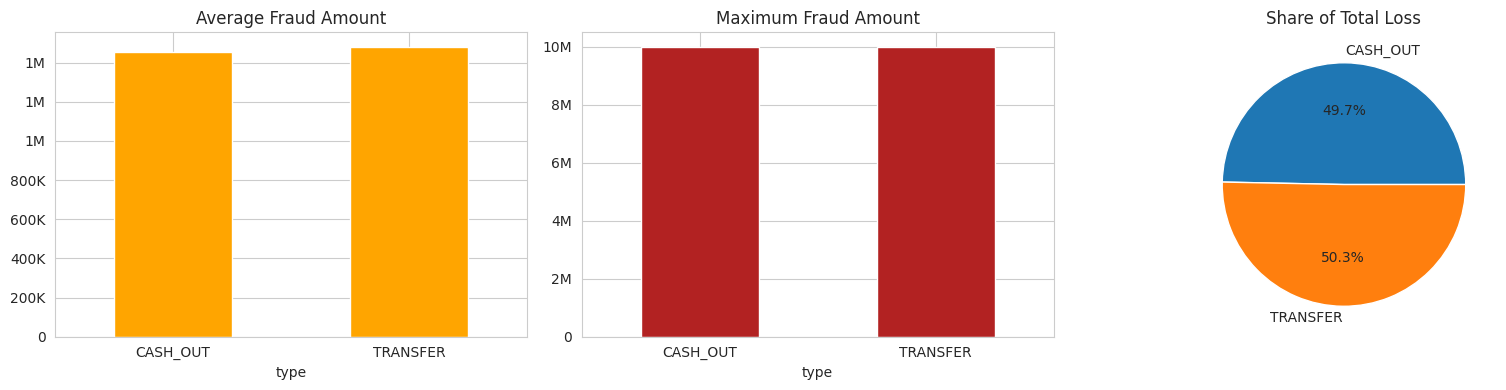

In [18]:
q4 = fraud.groupby('type', observed=True)['amount'].agg(fraud_count='size', average='mean', maximum='max', total='sum')
q4['share_of_total_loss_%'] = q4['total'] / q4['total'].sum() * 100
display(q4.round(0))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
q4['average'].plot.bar(ax=ax[0], color='orange'); ax[0].set_title('Average Fraud Amount')
q4['maximum'].plot.bar(ax=ax[1], color='firebrick'); ax[1].set_title('Maximum Fraud Amount')
q4['share_of_total_loss_%'].plot.pie(ax=ax[2], autopct='%1.1f%%'); ax[2].set_title('Share of Total Loss'); ax[2].set_ylabel('')
for a in ax[:2]:
    a.yaxis.set_major_formatter(FuncFormatter(money)); a.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

# 5. Do fraudsters follow a signature pattern, such as TRANSFER followed by CASH_OUT, to drain accounts?

Fraud TRANSFERs: 4,097 | Fraud CASH_OUTs: 4,116
CASH_OUTs made by an account that received a fraud TRANSFER: 0

Fraud with source account emptied (%):
type
CASH_OUT   99.100
TRANSFER   96.000
Name: is_drained, dtype: float64


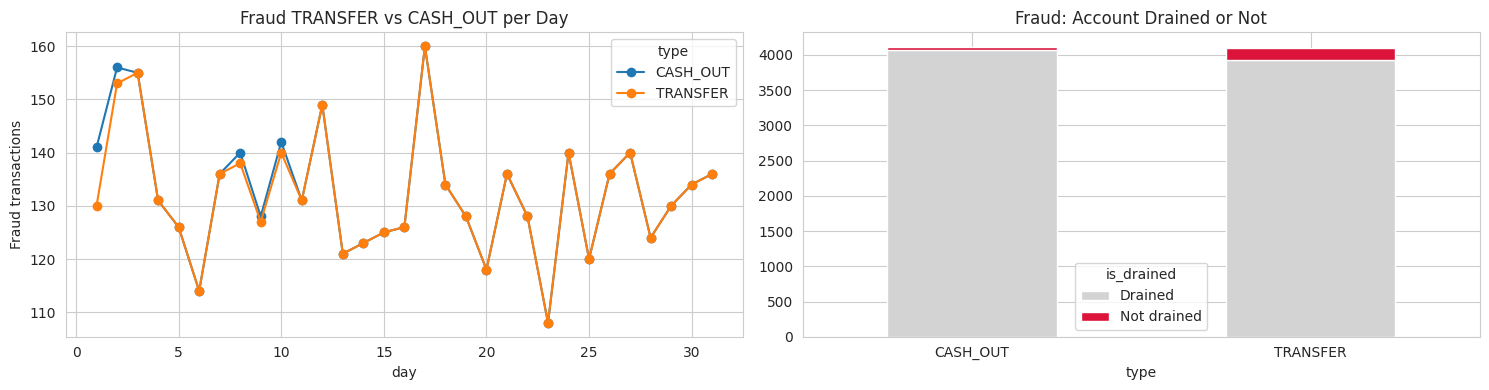

In [19]:
# 1. Chain test: does the receiver of a fraud TRANSFER later CASH_OUT as the sender?
tr_fraud = fraud[fraud['type'] == 'TRANSFER']
co_fraud = fraud[fraud['type'] == 'CASH_OUT']
linked = co_fraud[co_fraud['nameOrig'].isin(set(tr_fraud['nameDest']))]
print(f"Fraud TRANSFERs: {len(tr_fraud):,} | Fraud CASH_OUTs: {len(co_fraud):,}")
print(f"CASH_OUTs made by an account that received a fraud TRANSFER: {len(linked):,}")

# 2. Draining test
print("\nFraud with source account emptied (%):")
print((fraud.groupby('type', observed=True)['is_drained'].mean() * 100).round(1))

# 3. Charts
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
fraud_day = fraud.groupby(['day', 'type'], observed=True).size().unstack(fill_value=0)
fraud_day.plot(ax=ax[0], marker='o')
ax[0].set_title('Fraud TRANSFER vs CASH_OUT per Day'); ax[0].set_ylabel('Fraud transactions')

drain = pd.crosstab(fraud['type'], fraud['is_drained'].map({0: 'Not drained', 1: 'Drained'}))
drain.plot.bar(stacked=True, ax=ax[1], color=['lightgray', 'crimson'])
ax[1].set_title('Fraud: Account Drained or Not'); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

# 6. Which attack types (DoS, DDoS, PortScan, Brute Force, Web Attacks, Botnet, Infiltration) are most common and most damaging?

,flows,share_of_attacks_%
attack_group,,
DoS,193745,45.500
DDoS,128014,30.100
PortScan,90694,21.300
Brute Force (FTP/SSH),9150,2.100
Web Attack,2143,0.500
Botnet,1948,0.500
Infiltration,36,0.000
Heartbleed,11,0.000


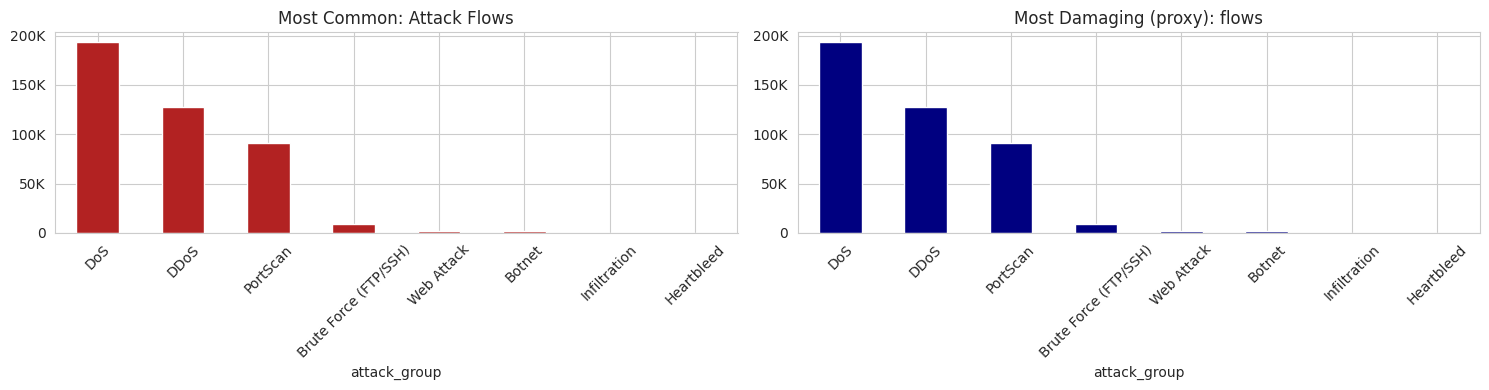

In [20]:
agg = {'flows': ('is_attack', 'size')}
if 'total_packets' in cic: agg['total_packets'] = ('total_packets', 'sum')
if 'total_bytes' in cic:   agg['total_bytes']   = ('total_bytes', 'sum')

q6 = att.groupby('attack_group', observed=True).agg(**agg).sort_values('flows', ascending=False)
q6['share_of_attacks_%'] = q6['flows'] / q6['flows'].sum() * 100
display(q6.round(1))

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
q6['flows'].plot.bar(ax=ax[0], color='firebrick'); ax[0].set_title('Most Common: Attack Flows')
ax[0].yaxis.set_major_formatter(FuncFormatter(count_fmt))
dmg = 'total_bytes' if 'total_bytes' in q6 else 'flows'
q6[dmg].plot.bar(ax=ax[1], color='navy'); ax[1].set_title(f'Most Damaging (proxy): {dmg}')
ax[1].yaxis.set_major_formatter(FuncFormatter(count_fmt))
for a in ax: a.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

# 7. Which attacks are hardest to detect (e.g., rare Infiltration or Web Attack XSS/SQL Injection), and why?

,flows,distance_from_benign,share_%
Label,,,
Heartbleed,11,2.243,0.000
Web Attack Sql Injection,21,0.071,0.001
Infiltration,36,0.785,0.001
Web Attack XSS,652,0.082,0.025
Web Attack Brute Force,1470,0.083,0.057
Bot,1948,0.054,0.076
SSH Patator,3219,0.108,0.125
DoS Slowhttptest,5228,0.533,0.203
DoS slowloris,5385,0.841,0.209


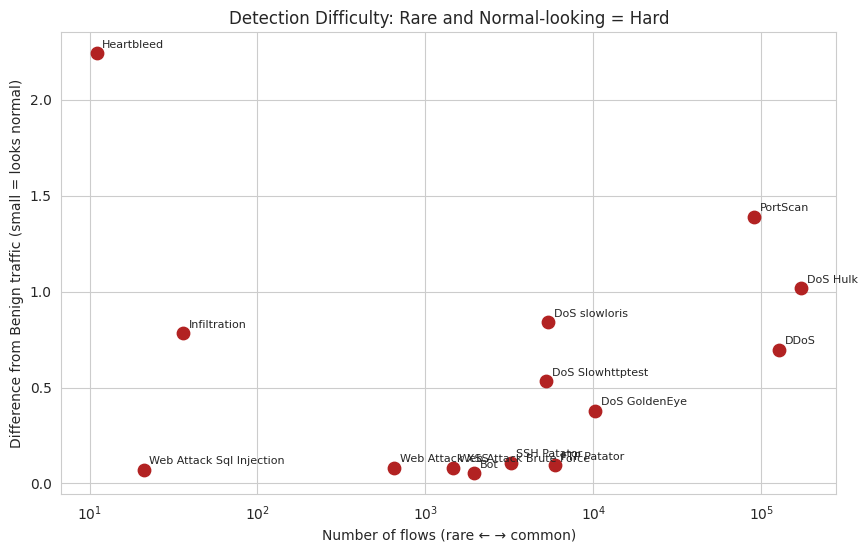

In [21]:
med = cic.groupby('Label')[feat].median()
scaled = (med - med.min()) / (med.max() - med.min() + 1e-9)

benign = [l for l in med.index if l.lower() == 'benign'][0]
distance = np.sqrt(((scaled - scaled.loc[benign]) ** 2).sum(axis=1)).drop(benign)

q7 = pd.DataFrame({'flows': cic['Label'].value_counts(), 'distance_from_benign': distance}).dropna()
q7['share_%'] = q7['flows'] / len(cic) * 100
display(q7.sort_values('flows').round(3))

plt.figure(figsize=(10, 6))
plt.scatter(q7['flows'], q7['distance_from_benign'], s=80, color='firebrick')
for lbl, r in q7.iterrows():
    plt.annotate(lbl, (r['flows'], r['distance_from_benign']), fontsize=8, xytext=(4, 4), textcoords='offset points')
plt.xscale('log'); plt.xlabel('Number of flows (rare ← → common)')
plt.ylabel('Difference from Benign traffic (small = looks normal)')
plt.title('Detection Difficulty: Rare and Normal-looking = Hard')
plt.show()

# 8. How do attackers' traffic behaviors differ from normal banking-like traffic?

,Benign,Attack,attack_vs_benign_x
Flow Duration,"32,817.000","6,031,838.000",183.800
Total Fwd Packets,2.000,4.000,2.000
Total Backward Packets,2.000,5.000,2.500
Flow Bytes/s,"4,529.150",143.290,0.030
Flow Packets/s,86.920,1.120,0.010
Packet Length Mean,60.800,777.530,12.790
Average Packet Size,77.000,831.800,10.800


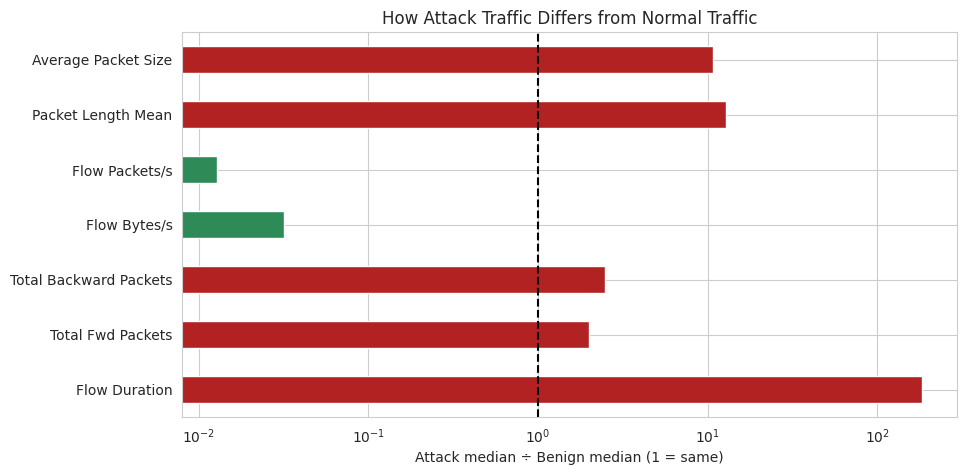

In [22]:
q8 = cic.groupby('is_attack')[feat].median().T
q8.columns = ['Benign', 'Attack']
q8['attack_vs_benign_x'] = (q8['Attack'] + 1e-9) / (q8['Benign'] + 1e-9)
display(q8.round(2))

ratio = q8['attack_vs_benign_x'].clip(1e-3, 1e3)
plt.figure(figsize=(10, 5))
ratio.plot.barh(color=np.where(ratio > 1, 'firebrick', 'seagreen'))
plt.axvline(1, color='black', linestyle='--')
plt.xscale('log'); plt.xlabel('Attack median ÷ Benign median (1 = same)')
plt.title('How Attack Traffic Differs from Normal Traffic')
plt.show()

# 9. Are there time-based patterns (by hour, day, or step) when fraud peaks?

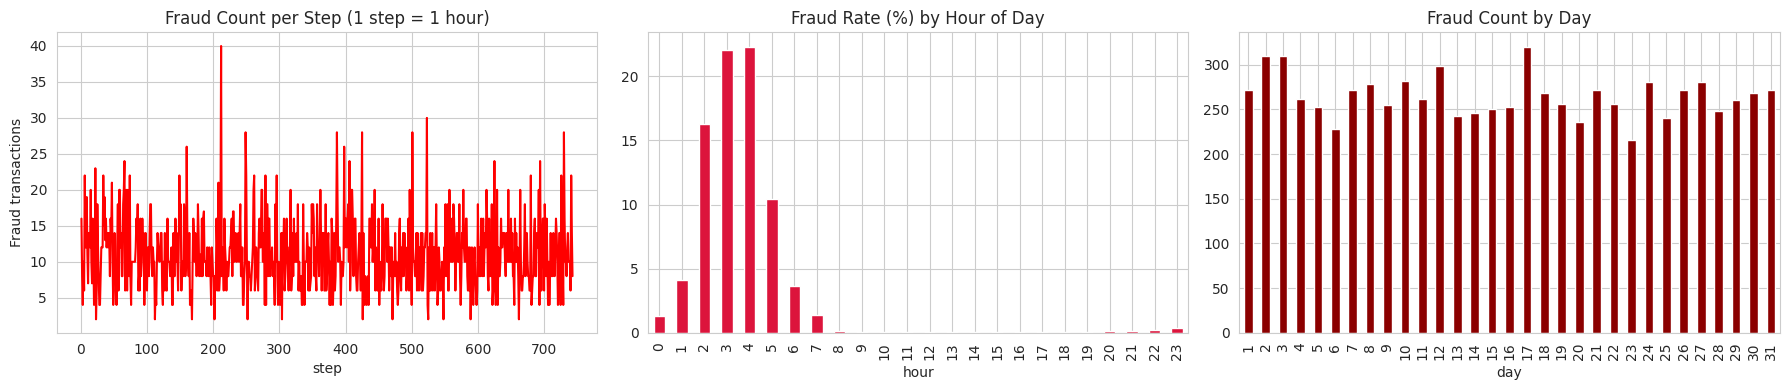

Peak fraud-rate hour : 4 (22.303%)
Peak fraud day       : 17
Top 5 steps by fraud :
 step
212    40
523    30
501    28
387    28
249    28
Name: count, dtype: int64

Fraud rate (%) by time of day:
time_of_day
Night (0-5)         4.622
Morning (6-11)      0.124
Afternoon (12-17)   0.075
Evening (18-23)     0.108
Name: isFraud, dtype: float64


In [23]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))

fraud.groupby('step').size().plot(ax=ax[0], color='red')
ax[0].set_title('Fraud Count per Step (1 step = 1 hour)'); ax[0].set_ylabel('Fraud transactions')

(paysim.groupby('hour')['isFraud'].mean() * 100).plot.bar(ax=ax[1], color='crimson')
ax[1].set_title('Fraud Rate (%) by Hour of Day')

fraud.groupby('day').size().plot.bar(ax=ax[2], color='darkred')
ax[2].set_title('Fraud Count by Day')
plt.tight_layout(); plt.show()

rate_hour = paysim.groupby('hour')['isFraud'].mean() * 100
print("Peak fraud-rate hour :", rate_hour.idxmax(), f"({rate_hour.max():.3f}%)")
print("Peak fraud day       :", fraud['day'].value_counts().idxmax())
print("Top 5 steps by fraud :\n", fraud['step'].value_counts().head(5))
print("\nFraud rate (%) by time of day:")
print((paysim.groupby('time_of_day', observed=True)['isFraud'].mean() * 100).round(3))

# 10. How can the bank prioritize alerts so investigators focus on the highest-risk cases first?

,transactions,fraud_count,fraud_value,% of transactions,% of fraud caught,% of fraud value,fraud_rate_%
priority,,,,,,,
P1 Critical,1882,1476,"5,190,510,165.110",0.030,17.972,43.052,78.427
P2 High,234850,3934,"4,563,822,403.360",3.691,47.900,37.854,1.675
P3 Medium,2428261,2803,"2,302,082,859.370",38.164,34.129,19.094,0.115
P4 Routine,3697627,0,0.000,58.115,0.000,0.000,0.000


Reviewing P1 + P2 means checking 3.721% of transactions, covering 65.9% of fraud and 80.9% of fraud money.


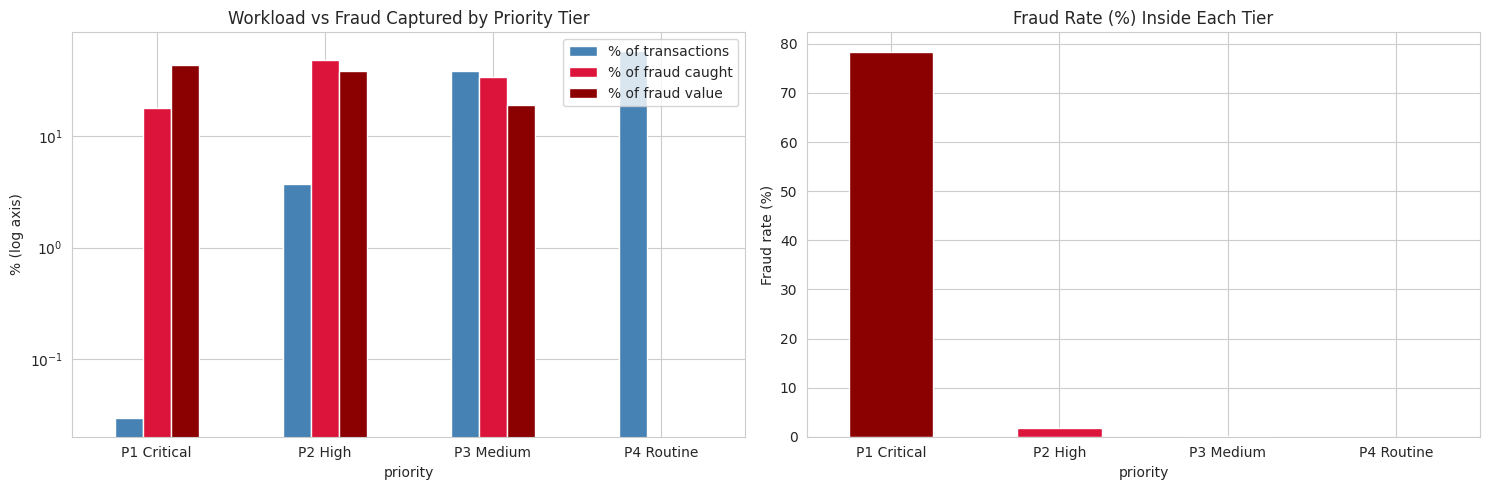


Top 15 alerts for investigators (P1 first, largest amount first):


,step,type,amount,oldbalanceOrg,newbalanceOrig,is_drained,priority,isFraud
4441,4,CASH_OUT,"10,000,000.000","10,000,000.000",0.000,1,P1 Critical,1
481251,19,CASH_OUT,"10,000,000.000","10,000,000.000",0.000,1,P1 Critical,1
586312,33,CASH_OUT,"10,000,000.000","10,000,000.000",0.000,1,P1 Critical,1
1030560,72,CASH_OUT,"10,000,000.000","10,000,000.000",0.000,1,P1 Critical,1
1030662,82,CASH_OUT,"10,000,000.000","10,000,000.000",0.000,1,P1 Critical,1
1030688,84,CASH_OUT,"10,000,000.000","10,000,000.000",0.000,1,P1 Critical,1
1030710,86,CASH_OUT,"10,000,000.000","10,000,000.000",0.000,1,P1 Critical,1
1055000,96,CASH_OUT,"10,000,000.000","10,000,000.000",0.000,1,P1 Critical,1
1059699,118,CASH_OUT,"10,000,000.000","10,000,000.000",0.000,1,P1 Critical,1
1141252,131,CASH_OUT,"10,000,000.000","10,000,000.000",0.000,1,P1 Critical,1


,flows,share_%,priority
attack_group,,,
DoS,193745,45.510,High volume: automate blocking
DDoS,128014,30.070,High volume: automate blocking
PortScan,90694,21.300,High volume: automate blocking
Brute Force (FTP/SSH),9150,2.150,Medium: analyst review
Web Attack,2143,0.500,Rare: manual threat hunt (hard to detect)
Botnet,1948,0.460,Rare: manual threat hunt (hard to detect)
Infiltration,36,0.010,Rare: manual threat hunt (hard to detect)
Heartbleed,11,0.000,Rare: manual threat hunt (hard to detect)


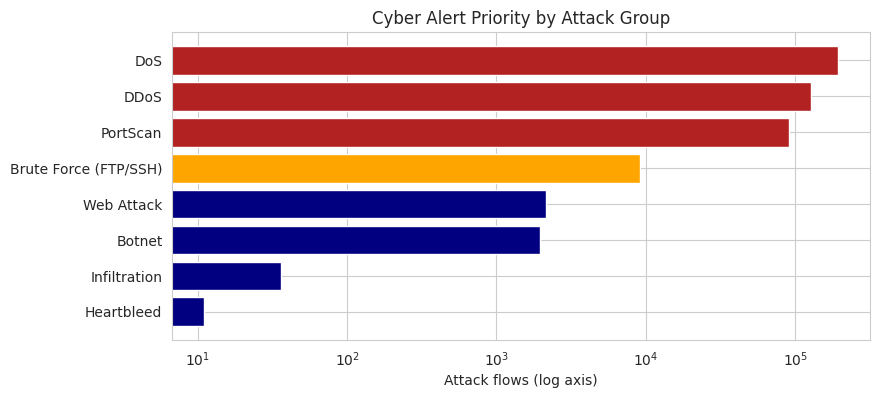

In [24]:
from matplotlib.ticker import FuncFormatter

def money(x, pos=None):
    if x >= 1e9: return f'{x/1e9:.1f}B'
    if x >= 1e6: return f'{x/1e6:.0f}M'
    if x >= 1e3: return f'{x/1e3:.0f}K'
    return f'{x:.0f}'

# ---------- 1. Segment fraud rate (observed) ----------
keys = ['type', 'is_drained', 'amount_band']
paysim['segment_fraud_rate_%'] = paysim.groupby(keys, observed=True)['isFraud'].transform('mean') * 100

# ---------- 2. Assign priority tiers ----------
tiers = ['P1 Critical', 'P2 High', 'P3 Medium', 'P4 Routine']
paysim['priority'] = pd.cut(paysim['segment_fraud_rate_%'],
                            bins=[-1, 0, 1, 10, 101],
                            labels=['P4 Routine', 'P3 Medium', 'P2 High', 'P1 Critical'])
paysim['priority'] = pd.Categorical(paysim['priority'], categories=tiers, ordered=True)

# ---------- 3. Workload vs fraud captured per tier ----------
t = paysim.groupby('priority', observed=False).agg(transactions=('isFraud', 'size'),
                                                  fraud_count=('isFraud', 'sum'))
t['fraud_value'] = paysim[paysim.isFraud == 1].groupby('priority', observed=False)['amount'].sum()
t = t.fillna(0)
t['% of transactions']   = t['transactions'] / t['transactions'].sum() * 100
t['% of fraud caught']   = t['fraud_count'] / t['fraud_count'].sum() * 100
t['% of fraud value']    = t['fraud_value'] / t['fraud_value'].sum() * 100
t['fraud_rate_%']        = t['fraud_count'] / t['transactions'].replace(0, np.nan) * 100
display(t.round(3))

print(f"Reviewing P1 + P2 means checking {t.loc[['P1 Critical','P2 High'], '% of transactions'].sum():.3f}% "
      f"of transactions, covering {t.loc[['P1 Critical','P2 High'], '% of fraud caught'].sum():.1f}% of fraud "
      f"and {t.loc[['P1 Critical','P2 High'], '% of fraud value'].sum():.1f}% of fraud money.")

# ---------- 4. Charts ----------
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
t[['% of transactions', '% of fraud caught', '% of fraud value']].plot.bar(
    ax=ax[0], color=['steelblue', 'crimson', 'darkred'])
ax[0].set_yscale('log'); ax[0].set_ylabel('% (log axis)')
ax[0].set_title('Workload vs Fraud Captured by Priority Tier')
ax[0].tick_params(axis='x', rotation=0)

t['fraud_rate_%'].plot.bar(ax=ax[1], color=['darkred', 'crimson', 'orange', 'lightgray'])
ax[1].set_title('Fraud Rate (%) Inside Each Tier'); ax[1].set_ylabel('Fraud rate (%)')
ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

# ---------- 5. Investigator queue: biggest P1 and P2 cases first ----------
queue = (paysim[paysim['priority'].isin(['P1 Critical', 'P2 High'])]
         .sort_values(['priority', 'amount'], ascending=[True, False])
         .head(15)[['step', 'type', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
                    'is_drained', 'priority', 'isFraud']])
print("\nTop 15 alerts for investigators (P1 first, largest amount first):")
display(queue)

# ---------- 6. Cyber alert tiers (by observed volume and rarity) ----------
cy = att['attack_group'].astype(str).value_counts().rename('flows').to_frame()
cy['share_%'] = cy['flows'] / cy['flows'].sum() * 100
cy['priority'] = np.select([cy['share_%'] >= 10, cy['share_%'] >= 1],
                           ['High volume: automate blocking', 'Medium: analyst review'],
                           default='Rare: manual threat hunt (hard to detect)')
display(cy.round(2))

colors = cy['priority'].map({'High volume: automate blocking': 'firebrick',
                             'Medium: analyst review': 'orange',
                             'Rare: manual threat hunt (hard to detect)': 'navy'})
plt.figure(figsize=(9, 4))
plt.barh(cy.index[::-1], cy['flows'][::-1], color=colors[::-1])
plt.xscale('log'); plt.xlabel('Attack flows (log axis)')
plt.title('Cyber Alert Priority by Attack Group')
plt.show()